In [12]:
## Import dependecies
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("Sample - Superstore.csv", encoding= "cp1252")

## Inspect first five rows, 
# check the number of rows and columns, 
# review columns names and data type,
# check missing values
# count exact duplicate rows

display(df.head())

print ("Dataset shape:", df.shape)

df.info()

print(df.isna().sum())

print ("Duplicate rows:", df.duplicated().sum())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Dataset shape: (9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-nu

In [5]:
## Convert date columns to datetime
# Review numerical summaries

df["Order_Date"] = pd.to_datetime(
    df["Order Date"],
    format = "%m/%d/%Y"
) 

display(df[["Sales", "Quantity", "Discount", "Profit"]].describe())


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [6]:
## Check for negative values
print("Negative sales:", (df["Sales"] < 0).sum())

## Check for zero or negative quantities
print ("Invalid quantites:", (df["Quantity"] <= 0).sum())

## Check discount range
print ("Discounts below 0:", (df["Discount"] < 0).sum())
print ("Discounts above 1:", (df["Discount"] > 1).sum())

## Investigate negative profit
loss_rows = df[df["Profit"] <0]

print ("Rows with negative profit:", len(loss_rows))
print ("Total record on profit loss rows:",
       round(loss_rows["Profit"].sum(), 2))

display(
    loss_rows[
        ["Order ID", "Product Name", "Category", "Sales", "Discount", "Profit"]
    ].head(10)
)

Negative sales: 0
Invalid quantites: 0
Discounts below 0: 0
Discounts above 1: 0
Rows with negative profit: 1871
Total record on profit loss rows: -156131.29


,Order ID,Product Name,Category,Sales,Discount,Profit
3,US-2015-108966,Bretford CR4500 Series Slim Rectangular Table,Furniture,957.5775,0.45,-383.0310
14,US-2015-118983,Holmes Replacement Filter for HEPA Air Cleaner...,Office Supplies,68.8100,0.80,-123.8580
15,US-2015-118983,Storex DuraTech Recycled Plastic Frosted Binders,Office Supplies,2.5440,0.80,-3.8160
23,US-2017-156909,"Global Deluxe Stacking Chair, Gray",Furniture,71.3720,0.30,-1.0196
27,US-2015-150630,"Riverside Palais Royal Lawyers Bookcase, Royal...",Furniture,3083.4300,0.50,-1665.0522
28,US-2015-150630,Avery Recycled Flexi-View Covers for Binding S...,Office Supplies,9.6180,0.70,-7.0532
32,US-2015-150630,"Acco Pressboard Covers with Storage Hooks, 14 ...",Office Supplies,6.8580,0.70,-5.7150
36,CA-2016-117590,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",Furniture,190.9200,0.60,-147.9630
38,CA-2015-117415,"Atlantic Metals Mobile 3-Shelf Bookcases, Cust...",Furniture,532.3992,0.32,-46.9764
39,CA-2015-117415,"Global Fabric Manager's Chair, Dark Gray",Furniture,212.0580,0.30,-15.1470


In [7]:
# Convert date columns
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%m/%d/%Y"
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="%m/%d/%Y"
)
# Profit margin as a decimal ratio
df["Profit Margin"] = df["Profit"] / df["Sales"]

# Month for grouping sales over time
df["Order Month"] = (
    df["Order Date"].dt.to_period("M").astype(str)
)

display(
    df[["Order Date", "Sales", "Profit",
        "Profit Margin", "Order Month"]].head()
)

,Order Date,Sales,Profit,Profit Margin,Order Month
0,2016-11-08,261.9600,41.9136,0.1600,2016-11
1,2016-11-08,731.9400,219.5820,0.3000,2016-11
2,2016-06-12,14.6200,6.8714,0.4700,2016-06
3,2015-10-11,957.5775,-383.0310,-0.4000,2015-10
4,2015-10-11,22.3680,2.5164,0.1125,2015-10


In [8]:
## Group sales data by product subcategory

subcategory_analysis = (
    df.groupby("Sub-Category")
    .agg(
       Total_Sales = ("Sales", "sum"),
       Total_Profit = ("Profit", "sum"),
       Units_Sold = ("Quantity", "sum"),
       Average_Disount = ("Discount", "mean"),
       Order_Lines = ("Order ID", "count")
    )
    .reset_index()
)

## Calculate profit margin

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"] * 100
)

## Sort by total profit, highest first

subcategory_analysis = subcategory_analysis.sort_values(
    "Total_Profit", ascending = False
)

display(subcategory_analysis.round(2))

,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Average_Disount,Order_Lines,Profit_Margin
6,Copiers,149528.03,55617.82,234,0.16,68,37.20
13,Phones,330007.05,44515.73,3289,0.15,889,13.49
0,Accessories,167380.32,41936.64,2976,0.08,775,25.05
12,Paper,78479.21,34053.57,5178,0.07,1370,43.39
3,Binders,203412.73,30221.76,5974,0.37,1523,14.86
5,Chairs,328449.10,26590.17,2356,0.17,617,8.10
14,Storage,223843.61,21278.83,3158,0.07,846,9.51
1,Appliances,107532.16,18138.01,1729,0.17,466,16.87
9,Furnishings,91705.16,13059.14,3563,0.14,957,14.24
7,Envelopes,16476.40,6964.18,906,0.08,254,42.27


In [9]:
## Identify biggest losses

loss_subcategories = subcategory_analysis[
    subcategory_analysis["Total_Profit"] < 0
].sort_values("Total_Profit")

loss_subcategories.round(2)

,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Average_Disount,Order_Lines,Profit_Margin
16,Tables,206965.53,-17725.48,1241,0.26,319,-8.56
4,Bookcases,114880.00,-3472.56,868,0.21,228,-3.02
15,Supplies,46673.54,-1189.10,647,0.08,190,-2.55


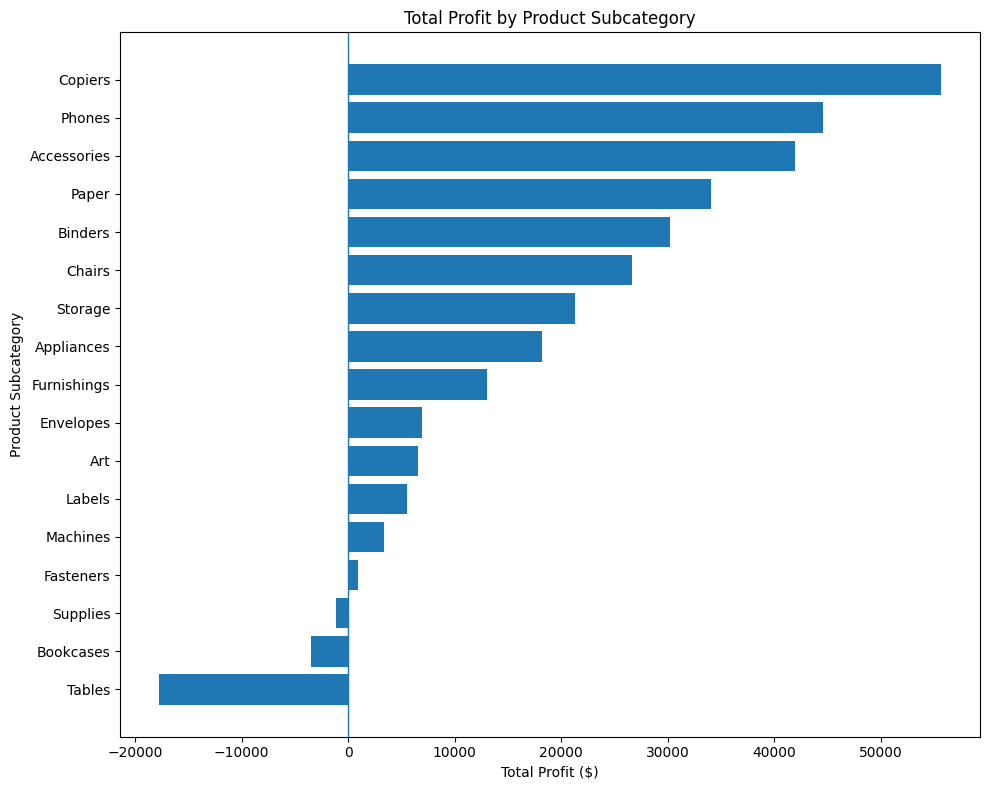

In [13]:
## Visualize results in a bar chart

chart_data = subcategory_analysis.sort_values("Total_Profit")

plt.figure(figsize = (10, 8))
plt.barh(
    chart_data["Sub-Category"],
    chart_data["Total_Profit"]
)

plt.axvline(0, linewidth=1)
plt.title("Total Profit by Product Subcategory")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Subcategory")
plt.tight_layout()
plt.show()

In [14]:

import pandas as pd

# Read the original CSV using its likely encoding
df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

# Replace non-breaking spaces with regular spaces
df = df.replace("\xa0", " ", regex=True)

# Save a clean UTF-8 CSV for PostgreSQL
df.to_csv("Sample_Superstore_Clean.csv", index=False, encoding="utf-8")

print("Cleaned file saved successfully!")
print(df.shape)


Cleaned file saved successfully!
(9994, 21)


In [15]:

import pandas as pd
import csv

# Read the original file
df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

# Clean special spaces
df = df.replace("\xa0", " ", regex=True)

# Export a PostgreSQL-friendly CSV
df.to_csv(
    "Superstore_PostgreSQL.csv",
    index=False,
    encoding="utf-8",
    quoting=csv.QUOTE_MINIMAL,
    quotechar='"',
    doublequote=True,
    lineterminator="\n"
)

print("Rows and columns:", df.shape)
print("New CSV created: Superstore_PostgreSQL.csv")


Rows and columns: (9994, 21)
New CSV created: Superstore_PostgreSQL.csv
